# Estoque e Vendas / Stock and Sales
**EN:** Beginner data analysis project: synthetic data, SQLite, SQL queries and charts (100% fake data, fixed seed).

**PT:** Projeto de análise de dados nível iniciante: dados sintéticos, SQLite, consultas SQL e gráficos (100% fictícios, seed fixa).

**Stages / Etapas:** 1 data generator · 2 SQLite database · 3 SQL queries · 4 charts and results

## Stage 1 - Synthetic data / Etapa 1 - Dados sintéticos

In [ ]:
# EN: Install dependencies in the first cell so the notebook runs after a session restart.
# PT: Instala as dependências na primeira célula para o notebook rodar após reiniciar a sessão.
%pip install -q "numpy>=1.24" "pandas>=2.0" "matplotlib>=3.7"

In [ ]:
import numpy as np
import pandas as pd

# EN: Fixed seed = same data on every run (reproducible).
# PT: Seed fixa = mesmos dados em toda execução (reproduzível).
SEED: int = 42
N_CLIENTES: int = 200
N_VENDAS: int = 3000
ANO: int = 2025

# EN: Fake catalog: (name, category, sale price in BRL).
# PT: Catálogo fictício: (nome, categoria, preço de venda em R$).
CATALOGO: list[tuple[str, str, float]] = [
    ("Água mineral 500ml", "Bebidas", 2.50),
    ("Refrigerante 2L", "Bebidas", 9.00),
    ("Suco de laranja 1L", "Bebidas", 7.50),
    ("Café pronto 250ml", "Bebidas", 5.00),
    ("Chá gelado 1,5L", "Bebidas", 8.00),
    ("Energético 269ml", "Bebidas", 8.50),
    ("Pão francês 1kg", "Padaria", 16.00),
    ("Pão de forma", "Padaria", 8.50),
    ("Bolo de cenoura", "Padaria", 14.00),
    ("Biscoito recheado", "Padaria", 4.50),
    ("Croissant", "Padaria", 6.50),
    ("Rosca doce", "Padaria", 9.00),
    ("Leite 1L", "Laticínios", 5.50),
    ("Iogurte natural 170g", "Laticínios", 3.50),
    ("Queijo mussarela 200g", "Laticínios", 14.00),
    ("Manteiga 200g", "Laticínios", 12.00),
    ("Requeijão 200g", "Laticínios", 8.00),
    ("Creme de leite 200g", "Laticínios", 4.50),
    ("Arroz 5kg", "Mercearia", 28.00),
    ("Feijão 1kg", "Mercearia", 8.50),
    ("Macarrão 500g", "Mercearia", 5.00),
    ("Óleo de soja 900ml", "Mercearia", 7.50),
    ("Açúcar 1kg", "Mercearia", 5.50),
    ("Farinha de trigo 1kg", "Mercearia", 6.00),
    ("Detergente 500ml", "Limpeza", 2.80),
    ("Sabão em pó 1kg", "Limpeza", 12.00),
    ("Desinfetante 1L", "Limpeza", 6.50),
    ("Água sanitária 1L", "Limpeza", 5.00),
    ("Esponja multiuso", "Limpeza", 3.00),
    ("Papel higiênico 12un", "Limpeza", 19.00),
]

# EN: Cities with weights (bigger weight = more customers). Real cities, fake customers.
# PT: Cidades com pesos (peso maior = mais clientes). Cidades reais, clientes fictícios.
CIDADES: dict[str, float] = {
    "São Paulo": 0.40,
    "Guarulhos": 0.12,
    "Osasco": 0.10,
    "Santo André": 0.10,
    "São Bernardo do Campo": 0.08,
    "Campinas": 0.08,
    "Santos": 0.07,
    "Sorocaba": 0.05,
}

# EN: Month weights = seasonality (December sells more, February sells less).
# PT: Pesos por mês = sazonalidade (dezembro vende mais, fevereiro vende menos).
PESO_MES: dict[int, float] = {
    1: 1.0, 2: 0.8, 3: 0.9, 4: 0.95, 5: 1.0, 6: 0.9,
    7: 1.0, 8: 1.0, 9: 1.0, 10: 1.1, 11: 1.2, 12: 1.5,
}

In [ ]:
def gerar_produtos(rng: np.random.Generator) -> pd.DataFrame:
    """Build the products table / Monta a tabela de produtos."""
    # EN: Cost is 55%-80% of the price, so profit is always positive.
    # PT: Custo é 55%-80% do preço, então o lucro é sempre positivo.
    linhas = []
    for id_produto, (nome, categoria, preco) in enumerate(CATALOGO, start=1):
        custo = round(preco * rng.uniform(0.55, 0.80), 2)
        linhas.append((id_produto, nome, categoria, preco, custo))
    return pd.DataFrame(
        linhas, columns=["id", "nome", "categoria", "preco", "custo"]
    )


def gerar_clientes(rng: np.random.Generator, n: int) -> pd.DataFrame:
    """Build the customers table (no names) / Monta a tabela de clientes (sem nomes)."""
    # EN: Only id + city: no personal data at all (LGPD-safe).
    # PT: Só id + cidade: nenhum dado pessoal (seguro para a LGPD).
    cidades = rng.choice(
        list(CIDADES.keys()), size=n, p=list(CIDADES.values())
    )
    return pd.DataFrame({"id": np.arange(1, n + 1), "cidade": cidades})


def gerar_vendas(
    rng: np.random.Generator,
    produtos: pd.DataFrame,
    clientes: pd.DataFrame,
    n: int,
    ano: int,
) -> pd.DataFrame:
    """Build the sales table / Monta a tabela de vendas."""
    # EN: Each day gets a weight from its month, so sales have seasonality.
    # PT: Cada dia recebe o peso do seu mês, então as vendas têm sazonalidade.
    dias = pd.date_range(f"{ano}-01-01", f"{ano}-12-31", freq="D")
    pesos_dia = np.array([PESO_MES[d.month] for d in dias])
    pesos_dia = pesos_dia / pesos_dia.sum()
    datas = dias[rng.choice(len(dias), size=n, p=pesos_dia)]

    # EN: Uneven popularity: some products sell much more than others.
    # PT: Popularidade desigual: alguns produtos vendem bem mais que outros.
    popularidade = rng.lognormal(mean=0.0, sigma=0.4, size=len(produtos))
    popularidade = popularidade / popularidade.sum()

    vendas = pd.DataFrame(
        {
            # EN: ISO text (YYYY-MM-DD) because SQLite has no date type.
            # PT: Texto ISO (AAAA-MM-DD) porque o SQLite não tem tipo data.
            "data": datas.strftime("%Y-%m-%d"),
            "id_produto": rng.choice(produtos["id"], size=n, p=popularidade),
            "id_cliente": rng.choice(clientes["id"], size=n),
            "quantidade": rng.integers(1, 6, size=n),
        }
    )
    # EN: Sort by date first, then create ids, so ids follow time order.
    # PT: Ordena por data antes de criar os ids, para o id seguir a ordem do tempo.
    vendas = vendas.sort_values("data").reset_index(drop=True)
    vendas.insert(0, "id", np.arange(1, n + 1))
    return vendas


def gerar_estoque(rng: np.random.Generator, produtos: pd.DataFrame) -> pd.DataFrame:
    """Build the stock table / Monta a tabela de estoque."""
    n = len(produtos)
    return pd.DataFrame(
        {
            "id_produto": produtos["id"],
            "quantidade_atual": rng.integers(0, 81, size=n),
            "estoque_minimo": rng.integers(10, 41, size=n),
        }
    )

In [ ]:
def validar_dados(
    produtos: pd.DataFrame,
    clientes: pd.DataFrame,
    vendas: pd.DataFrame,
    estoque: pd.DataFrame,
) -> None:
    """Check basic data rules / Confere regras básicas dos dados."""
    # EN: Fail early if something is wrong, before building the database.
    # PT: Falha cedo se algo estiver errado, antes de montar o banco.
    assert (produtos["custo"] < produtos["preco"]).all(), "custo >= preco"
    assert vendas["id_produto"].isin(produtos["id"]).all(), "produto inexistente"
    assert vendas["id_cliente"].isin(clientes["id"]).all(), "cliente inexistente"
    assert estoque["id_produto"].isin(produtos["id"]).all(), "estoque órfão"
    assert not any(
        df.isnull().any().any() for df in (produtos, clientes, vendas, estoque)
    ), "há valores nulos"
    abaixo = (estoque["quantidade_atual"] < estoque["estoque_minimo"]).sum()
    assert abaixo > 0, "nenhum produto abaixo do mínimo (pergunta 3 ficaria vazia)"


# EN: One rng, always called in the same order = same result every run.
# PT: Um único rng, sempre chamado na mesma ordem = mesmo resultado em toda execução.
rng = np.random.default_rng(SEED)
produtos = gerar_produtos(rng)
clientes = gerar_clientes(rng, N_CLIENTES)
vendas = gerar_vendas(rng, produtos, clientes, N_VENDAS, ANO)
estoque = gerar_estoque(rng, produtos)

validar_dados(produtos, clientes, vendas, estoque)

# EN: Only synthetic rows are shown here, safe to keep in the notebook output.
# PT: Aqui só aparecem linhas sintéticas, seguro manter no output do notebook.
for nome_tabela, tabela in {
    "produtos": produtos, "clientes": clientes,
    "vendas": vendas, "estoque": estoque,
}.items():
    print(f"{nome_tabela}: {len(tabela)} linhas")
vendas.head()

produtos: 30 linhas
clientes: 200 linhas
vendas: 3000 linhas
estoque: 30 linhas


,id,data,id_produto,id_cliente,quantidade
0,1,2025-01-01,2,86,1
1,2,2025-01-01,9,29,1
2,3,2025-01-01,3,26,5
3,4,2025-01-01,10,169,4
4,5,2025-01-01,3,111,1


## Stage 2 - SQLite database / Etapa 2 - Banco SQLite

In [ ]:
import sqlite3
from pathlib import Path

import pandas as pd

DB_PATH = Path("data") / "estoque_vendas.db"

# EN: Schema with keys and checks, so bad data is rejected by the database.
# PT: Esquema com chaves e regras, para o banco recusar dado errado.
SCHEMA = """
CREATE TABLE produtos (
    id        INTEGER PRIMARY KEY,
    nome      TEXT NOT NULL,
    categoria TEXT NOT NULL,
    preco     REAL NOT NULL CHECK (preco > 0),
    custo     REAL NOT NULL CHECK (custo > 0)
);
CREATE TABLE clientes (
    id     INTEGER PRIMARY KEY,
    cidade TEXT NOT NULL
);
CREATE TABLE vendas (
    id         INTEGER PRIMARY KEY,
    data       TEXT NOT NULL,  -- EN: ISO 'YYYY-MM-DD' / PT: formato ISO
    id_produto INTEGER NOT NULL REFERENCES produtos(id),
    id_cliente INTEGER NOT NULL REFERENCES clientes(id),
    quantidade INTEGER NOT NULL CHECK (quantidade > 0)
);
CREATE TABLE estoque (
    id_produto      INTEGER PRIMARY KEY REFERENCES produtos(id),
    quantidade_atual INTEGER NOT NULL CHECK (quantidade_atual >= 0),
    estoque_minimo   INTEGER NOT NULL CHECK (estoque_minimo >= 0)
);
"""

# EN: Insert order matters: parent tables first, then tables with foreign keys.
# PT: A ordem importa: primeiro as tabelas "pai", depois as que usam chave estrangeira.
ORDEM = ["produtos", "clientes", "vendas", "estoque"]


def criar_banco(tabelas: dict[str, pd.DataFrame], caminho: Path = DB_PATH) -> Path:
    """Recreate the SQLite database from scratch and load all tables.

    Args:
        tabelas: DataFrames keyed by table name.
        caminho: Where the .db file will be written.

    Returns:
        Path of the created database.
    """
    # EN: Delete the old file so every run starts clean.
    # PT: Apaga o arquivo antigo para toda execução começar limpa.
    caminho.parent.mkdir(parents=True, exist_ok=True)
    caminho.unlink(missing_ok=True)

    with sqlite3.connect(caminho) as conn:
        # EN: SQLite ignores foreign keys unless this is turned on per connection.
        # PT: O SQLite ignora chaves estrangeiras se isto não for ligado.
        conn.execute("PRAGMA foreign_keys = ON")
        conn.executescript(SCHEMA)
        for nome in ORDEM:
            # EN: "append" keeps our schema; "replace" would drop the constraints.
            # PT: "append" mantém nosso esquema; "replace" apagaria as regras.
            tabelas[nome].to_sql(nome, conn, if_exists="append", index=False)
    return caminho

In [ ]:
def verificar_banco(caminho: Path = DB_PATH) -> pd.DataFrame:
    """Count rows per table and check for broken foreign keys."""
    with sqlite3.connect(caminho) as conn:
        conn.execute("PRAGMA foreign_keys = ON")
        contagens = {
            t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ORDEM
        }
        # EN: Empty result means no sale points to a missing product/customer.
        # PT: Resultado vazio = nenhuma venda aponta para produto/cliente inexistente.
        quebradas = conn.execute("PRAGMA foreign_key_check").fetchall()
    assert not quebradas, f"Foreign key problems: {quebradas}"
    return pd.DataFrame({"linhas": contagens})


# EN: Map table names to the DataFrames built in stage 1.
# PT: Liga o nome de cada tabela aos DataFrames criados na etapa 1.
tabelas = {
    "produtos": produtos,
    "clientes": clientes,
    "vendas": vendas,
    "estoque": estoque,
}
criar_banco(tabelas)
verificar_banco()

,linhas
produtos,30
clientes,200
vendas,3000
estoque,30


## Stage 3 - SQL queries / Etapa 3 - Consultas SQL
**EN:** One query per question (JOIN, GROUP BY, filters).

**PT:** Uma consulta por pergunta (JOIN, GROUP BY, filtros).

In [ ]:
import sqlite3
from pathlib import Path

import pandas as pd


def executar_consulta(sql: str, caminho: Path = DB_PATH) -> pd.DataFrame:
    """Run a SELECT and return a DataFrame / Roda um SELECT e devolve um DataFrame."""
    # EN: Open the database, run the query, and always close the connection.
    # PT: Abre o banco, roda a consulta e sempre fecha a conexão.
    with sqlite3.connect(caminho) as conn:
        return pd.read_sql_query(sql, conn)

In [ ]:
# EN: One query per business question. Each JOIN links tables by their keys.
# PT: Uma consulta por pergunta. Cada JOIN liga as tabelas pelas chaves.

# EN: Q1 - Top 5 products by units sold.
# PT: P1 - Os 5 produtos mais vendidos em unidades.
SQL_TOP_PRODUTOS = """
SELECT p.nome,
       SUM(v.quantidade) AS unidades_vendidas
FROM vendas v
JOIN produtos p ON p.id = v.id_produto
GROUP BY p.id, p.nome
ORDER BY unidades_vendidas DESC
LIMIT 5;
"""

# EN: Q2 - Profit per category = (price - cost) * quantity.
# PT: P2 - Lucro por categoria = (preço - custo) * quantidade.
SQL_LUCRO_CATEGORIA = """
SELECT p.categoria,
       ROUND(SUM((p.preco - p.custo) * v.quantidade), 2) AS lucro
FROM vendas v
JOIN produtos p ON p.id = v.id_produto
GROUP BY p.categoria
ORDER BY lucro DESC;
"""

# EN: Q3 - Products below the minimum stock (WHERE filters rows).
# PT: P3 - Produtos abaixo do estoque mínimo (WHERE filtra linhas).
SQL_ABAIXO_MINIMO = """
SELECT p.nome,
       e.quantidade_atual,
       e.estoque_minimo,
       e.estoque_minimo - e.quantidade_atual AS falta
FROM estoque e
JOIN produtos p ON p.id = e.id_produto
WHERE e.quantidade_atual < e.estoque_minimo
ORDER BY falta DESC;
"""

# EN: Q4 - Revenue per month. substr() cuts 'YYYY-MM-DD' into 'YYYY-MM'.
# PT: P4 - Faturamento por mês. substr() corta 'AAAA-MM-DD' em 'AAAA-MM'.
SQL_VENDAS_MES = """
SELECT substr(v.data, 1, 7) AS mes,
       ROUND(SUM(v.quantidade * p.preco), 2) AS faturamento
FROM vendas v
JOIN produtos p ON p.id = v.id_produto
GROUP BY mes
ORDER BY faturamento DESC;
"""

# EN: Q5 - Revenue per customer city (2 JOINs: products and customers).
# PT: P5 - Faturamento por cidade do cliente (2 JOINs: produtos e clientes).
SQL_VENDAS_CIDADE = """
SELECT c.cidade,
       ROUND(SUM(v.quantidade * p.preco), 2) AS faturamento
FROM vendas v
JOIN produtos p ON p.id = v.id_produto
JOIN clientes c ON c.id = v.id_cliente
GROUP BY c.cidade
ORDER BY faturamento DESC;
"""

top_produtos = executar_consulta(SQL_TOP_PRODUTOS)
lucro_categoria = executar_consulta(SQL_LUCRO_CATEGORIA)
abaixo_minimo = executar_consulta(SQL_ABAIXO_MINIMO)
vendas_mes = executar_consulta(SQL_VENDAS_MES)
vendas_cidade = executar_consulta(SQL_VENDAS_CIDADE)

top_produtos

,nome,unidades_vendidas
0,Refrigerante 2L,865
1,Manteiga 200g,433
2,Bolo de cenoura,420
3,Feijão 1kg,411
4,Pão francês 1kg,380


## Stage 4 - Charts and results / Etapa 4 - Gráficos e resultados

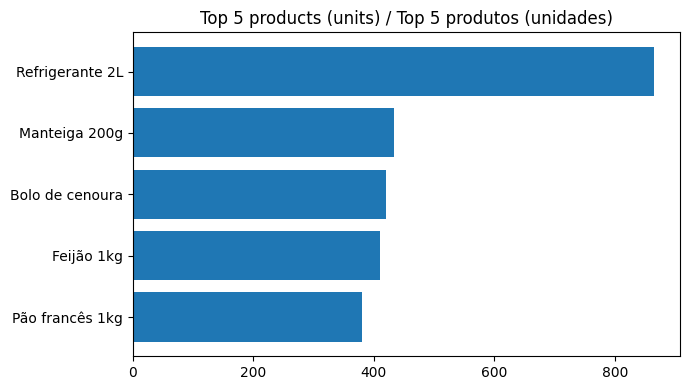

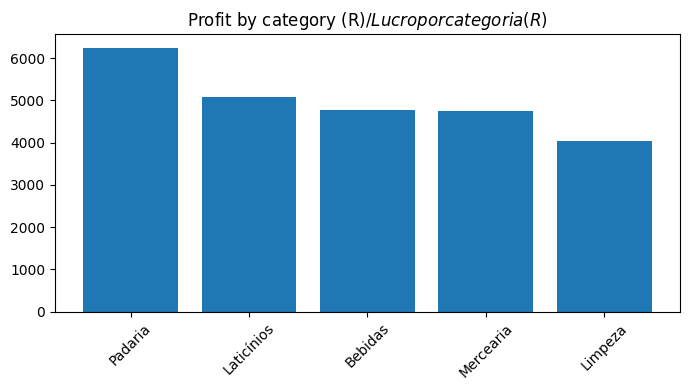

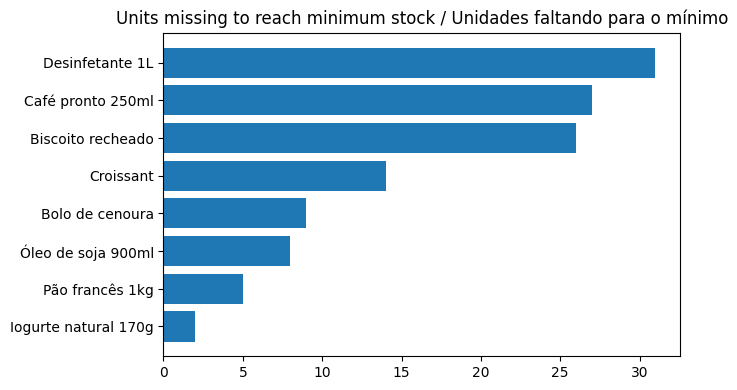

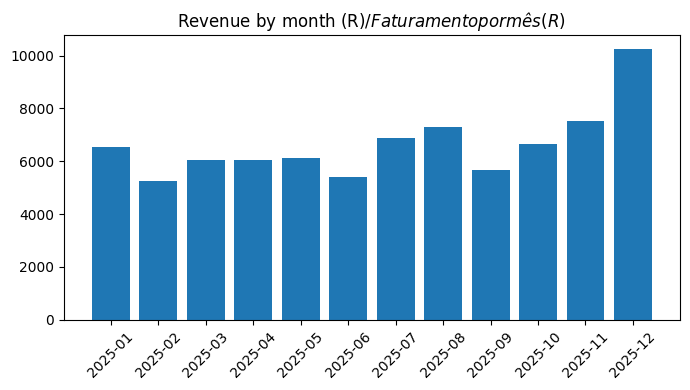

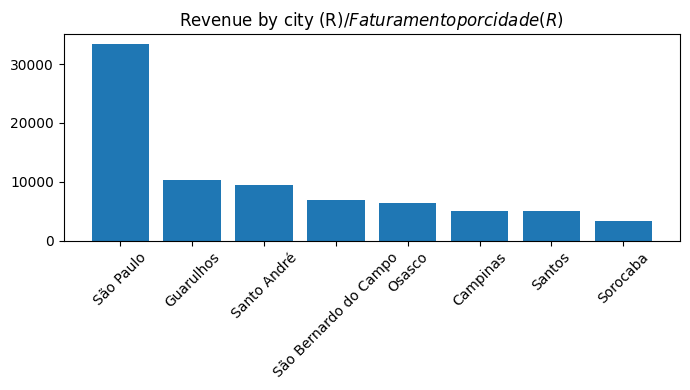

In [ ]:
import matplotlib.pyplot as plt

IMG_DIR = Path("img")


def grafico_barras(
    df: pd.DataFrame,
    x: str,
    y: str,
    titulo: str,
    arquivo: str,
    horizontal: bool = False,
) -> None:
    """Draw a bar chart and save it as a small PNG / Desenha e salva um gráfico de barras."""
    # EN: Small figure + low dpi keeps the PNG light (a few KB).
    # PT: Figura pequena + dpi baixo mantém o PNG leve (poucos KB).
    IMG_DIR.mkdir(exist_ok=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    if horizontal:
        ax.barh(df[x], df[y])
        ax.invert_yaxis()  # EN: biggest on top / PT: maior em cima
    else:
        ax.bar(df[x], df[y])
        ax.tick_params(axis="x", rotation=45)
    ax.set_title(titulo)
    fig.tight_layout()
    fig.savefig(IMG_DIR / arquivo, dpi=100)
    plt.show()


grafico_barras(
    top_produtos, "nome", "unidades_vendidas",
    "Top 5 products (units) / Top 5 produtos (unidades)",
    "01_top_produtos.png", horizontal=True,
)
grafico_barras(
    lucro_categoria, "categoria", "lucro",
    "Profit by category (R$) / Lucro por categoria (R$)",
    "02_lucro_categoria.png",
)
grafico_barras(
    abaixo_minimo, "nome", "falta",
    "Units missing to reach minimum stock / Unidades faltando para o mínimo",
    "03_abaixo_minimo.png", horizontal=True,
)
# EN: Sort months in time order for the chart (the SQL sorted by revenue).
# PT: Ordena os meses no tempo para o gráfico (o SQL ordenou por faturamento).
grafico_barras(
    vendas_mes.sort_values("mes"), "mes", "faturamento",
    "Revenue by month (R$) / Faturamento por mês (R$)",
    "04_vendas_mes.png",
)
grafico_barras(
    vendas_cidade, "cidade", "faturamento",
    "Revenue by city (R$) / Faturamento por cidade (R$)",
    "05_vendas_cidade.png",
)

In [ ]:
def resumir_resultados() -> None:
    """Print the answer to each question / Imprime a resposta de cada pergunta."""
    # EN: Values come from the query results, nothing typed by hand.
    # PT: Os valores vêm do resultado das consultas, nada digitado à mão.
    print("1) Top 5:", ", ".join(top_produtos["nome"]))
    melhor_cat = lucro_categoria.iloc[0]
    print(f"2) Categoria mais lucrativa: {melhor_cat['categoria']} "
          f"(R$ {melhor_cat['lucro']:.2f})")
    print(f"3) Produtos abaixo do mínimo: {len(abaixo_minimo)}")
    melhor_mes = vendas_mes.iloc[0]
    print(f"4) Mês com mais faturamento: {melhor_mes['mes']} "
          f"(R$ {melhor_mes['faturamento']:.2f})")
    melhor_cidade = vendas_cidade.iloc[0]
    print(f"5) Cidade que mais compra: {melhor_cidade['cidade']} "
          f"(R$ {melhor_cidade['faturamento']:.2f})")


resumir_resultados()

1) Top 5: Refrigerante 2L, Manteiga 200g, Bolo de cenoura, Feijão 1kg, Pão francês 1kg
2) Categoria mais lucrativa: Padaria (R$ 6249.32)
3) Produtos abaixo do mínimo: 8
4) Mês com mais faturamento: 2025-12 (R$ 10255.50)
5) Cidade que mais compra: São Paulo (R$ 33382.30)
